In [19]:
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
from dotenv import load_dotenv 
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool 
from langgraph.graph import StateGraph,START,END
from typing import Annotated ,TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage,BaseMessage
from langgraph.prebuilt import ToolNode,tools_condition

In [2]:
load_dotenv()

True

In [3]:
llm=ChatOpenAI(model="gpt-4o-mini")

In [6]:
loader=PyPDFLoader("Foundations-of-Machine-Learning-Mehryar-Mohri-Afshin-Rostamizadeh-Ameet-Talwalkar.pdf")
docs=loader.load()

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/CIVJZZ+CMBX12', '/FirstChar': 70, '/FontDescriptor': IndirectObject(515, 0, 2795342965456), '/LastChar': 117, '/Subtype': '/Type1', '/Type': '/Font', '/Widths': IndirectObject(518, 0, 2795342965456)}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/AAAAAH+CMBX10', '/FirstChar': 0, '/FontDescriptor': IndirectObject(521, 0, 2795342965456), '/LastChar': 122, '/Subtype': '/Type1', '/Type': '/Font', '/Widths': IndirectObject(523, 0, 2795342965456)}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/AAAAEX+CMR10', '/FirstChar': 0, '/FontDescriptor': IndirectObject(525, 0, 2795342965456), '/LastChar': 127, 

In [7]:
len(docs)

505

In [8]:
splitter=RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=200)
chunks=splitter.split_documents(docs)

In [9]:
len(chunks)

1368

In [12]:

embeddings = OpenAIEmbeddings(model='text-embedding-3-small')
vector_store = FAISS.from_documents(chunks, embeddings)

In [13]:

vector_store

In [14]:

retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [15]:
@tool
def rag_tool(query):

    """
    Retrieve relevant information from the pdf document.
    Use this tool when the user asks factual / conceptual questions
    that might be answered from the stored documents.
    """
    result = retriever.invoke(query)

    context = [doc.page_content for doc in result]
    metadata = [doc.metadata for doc in result]

    return {
        'query': query,
        'context': context,
        'metadata': metadata
    }


In [16]:

tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [17]:

class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [18]:
def chat_node(state: ChatState):

    messages = state['messages']

    response = llm_with_tools.invoke(messages)

    return {'messages': [response]}

In [20]:
tool_node = ToolNode(tools)


In [21]:

graph = StateGraph(ChatState)

graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge('tools', 'chat_node')

chatbot = graph.compile()

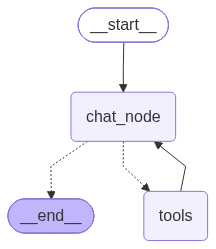

In [22]:
chatbot

In [23]:
result = chatbot.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "Using the pdf notes, explain how to find the ideal value of K in KNN"
                )
            )
        ]
    }
)

In [24]:
print(result['messages'][-1].content)

To find the ideal value of \( K \) in K-Nearest Neighbors (KNN), the following strategies are often employed:

1. **Cross-validation**: This is one of the most effective methods to select the optimal \( K \). You can use techniques like k-fold cross-validation, where the dataset is split into \( k \) subsets. The model is trained on \( k-1 \) subsets and tested on the remaining subset. This process is repeated for different values of \( K \), and the value which gives the best cross-validation score is chosen.

2. **Error analysis**: Track the model's performance as you vary \( K \). Plotting the training and validation error against different values of \( K \) can help you observe trends such as overfitting (high training accuracy and low validation accuracy) and underfitting (low accuracy for both). The ideal \( K \) typically balances these metrics.

3. **Leave-One-Out Cross-Validation (LOOCV)**: This is a special case of cross-validation where you leave one sample out of the traini